# RESCALE TEST COPY of `figure_4_main.ipynb` (made 2026-11-09)

For testing print-size font rescaling (checklist item Q). The original notebook is untouched.
`save_dir` points to `platform_paper_figures/figure_4_rescale_test/`, so nothing here overwrites the final figure exports.


**Saving is OFF by default:** the cell right after the setup cell sets `SAVE_FIGS = False`, which blocks all figure saves and stats writes. Turn it on only once the rescaled layout looks right.

## Figure 4 - Cell-type specific coding and GLM analysis


In [1]:
import visual_behavior_glm.GLM_visualization_tools as gvt
import visual_behavior_glm.GLM_fit_dev as gfd
import visual_behavior_glm.GLM_cell_metrics as gcm
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import visual_behavior.data_access.loading as loading
import visual_behavior.data_access.utilities as utilities
import visual_behavior.visualization.utils as utils

from visual_behavior.dimensionality_reduction.clustering import plotting
from visual_behavior.dimensionality_reduction.clustering import processing

import visual_behavior.visualization.ophys.glm_example_plots as gep
import visual_behavior.visualization.ophys.platform_paper_figures as ppf
import visual_behavior.visualization.ophys.platform_single_cell_examples as pse

from allensdk.brain_observatory.behavior.behavior_project_cache import VisualBehaviorOphysProjectCache



%load_ext autoreload
%autoreload 2
%matplotlib inline

/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/xarray/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/requests/__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain 

In [2]:
sns.set_context('notebook', font_scale=1.5, rc={'lines.markeredgewidth': 1})

glm_version = '24_events_all_L2_optimize_by_session'

save_dir = os.path.join(loading.get_figures_save_dir(), 'platform_paper_figures', 'figure_4_rescale_test')
if not os.path.exists(save_dir):
    os.makedirs(save_dir)

In [3]:
# --- RESCALE TEST: saving switch -------------------------------------------
# While SAVE_FIGS is False, nothing is written: every Figure.savefig / plt.savefig
# call is skipped, and so are pandas/numpy writes into save_dir (component stats).
# Figures still render inline. Set SAVE_FIGS = True and re-run this cell to save
# (outputs go to save_dir, the *_rescale_test folder, never the original figure folder).
SAVE_FIGS = False

import matplotlib.figure as _mfig, matplotlib.pyplot as _plt, pandas as _pd, numpy as _np
_ORIG = globals().setdefault('_ORIG_WRITERS', {
    'fig': _mfig.Figure.savefig, 'plt': _plt.savefig,
    'csv': _pd.DataFrame.to_csv, 'xlsx': _pd.DataFrame.to_excel, 'h5': _pd.DataFrame.to_hdf,
    'pkl': _pd.DataFrame.to_pickle, 'scsv': _pd.Series.to_csv, 'npsave': _np.save})

def _in_save_dir(path):
    return isinstance(path, (str, os.PathLike)) and os.path.abspath(str(path)).startswith(os.path.abspath(save_dir))

def _skip_fig(*a, **k):
    print('[SAVE_FIGS=False] skipped figure save:', os.path.basename(str(a[1] if len(a) > 1 else a[0])) if a else '')

def _guard(orig, name):
    def f(obj, path=None, *a, **k):
        if _in_save_dir(path):
            print(f'[SAVE_FIGS=False] skipped {name}:', os.path.basename(str(path)))
            return None
        return orig(obj, path, *a, **k)
    return f

if SAVE_FIGS:
    _mfig.Figure.savefig = _ORIG['fig']; _plt.savefig = _ORIG['plt']
    _pd.DataFrame.to_csv = _ORIG['csv']; _pd.DataFrame.to_excel = _ORIG['xlsx']
    _pd.DataFrame.to_hdf = _ORIG['h5']; _pd.DataFrame.to_pickle = _ORIG['pkl']
    _pd.Series.to_csv = _ORIG['scsv']; _np.save = _ORIG['npsave']
    print('Saving ON ->', save_dir)
else:
    _mfig.Figure.savefig = lambda self, *a, **k: _skip_fig(None, *a)
    _plt.savefig = lambda *a, **k: _skip_fig(None, *a)
    _pd.DataFrame.to_csv = _guard(_ORIG['csv'], 'csv'); _pd.DataFrame.to_excel = _guard(_ORIG['xlsx'], 'xlsx')
    _pd.DataFrame.to_hdf = _guard(_ORIG['h5'], 'h5'); _pd.DataFrame.to_pickle = _guard(_ORIG['pkl'], 'pkl')
    _pd.Series.to_csv = _guard(_ORIG['scsv'], 'csv')
    _np.save = lambda file, *a, **k: (print('[SAVE_FIGS=False] skipped np.save:', os.path.basename(str(file)))
                                      if _in_save_dir(file) else _ORIG['npsave'](file, *a, **k))
    print('Saving OFF (SAVE_FIGS=False). Figures display inline only.')

Saving OFF (SAVE_FIGS=False). Figures display inline only.


### Data Loading

#### Metadata Tables

In [4]:
# AllenSDK cache
platform_cache_dir = loading.get_platform_analysis_cache_dir()
cache = loading._get_cache()

# Curated metadata tables
metadata_tables_dir = loading.get_metadata_tables_dir()
experiments_table = pd.read_csv(os.path.join(metadata_tables_dir, 'all_ophys_experiments_table.csv'), index_col=0)
platform_experiments = pd.read_csv(os.path.join(metadata_tables_dir, 'platform_paper_ophys_experiments_table.csv'), index_col=0)
platform_cells_table = pd.read_csv(os.path.join(metadata_tables_dir, 'platform_paper_ophys_cells_table.csv'), index_col=0)
matched_cells_table = pd.read_csv(os.path.join(metadata_tables_dir, 'platform_paper_matched_ophys_cells_table.csv'), index_col=0)

# Relevant IDs
matched_cells = matched_cells_table.cell_specimen_id.unique()
matched_experiments = matched_cells_table.ophys_experiment_id.unique()

# Cre lines, cell types, and palette for plotting
cre_lines = np.sort(platform_cells_table.cre_line.unique())
cell_types = utils.get_cell_types()
experience_levels = utils.get_experience_levels()
palette = utils.get_experience_level_colors()


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

#### GLM results

In [5]:

# GLM results loading
glm_results_dir = loading.get_glm_results_dir()
run_params = pd.read_pickle(os.path.join(glm_results_dir, glm_version + '_run_params.pkl'))
run_params['figure_dir'] = os.path.join(save_dir, 'coding_scores_and_kernels')

kernels = run_params['kernels']

all_weights_df = pd.read_hdf(os.path.join(glm_results_dir, 'weights_df.h5'), key='df')
all_results = pd.read_hdf(os.path.join(glm_results_dir, 'all_results.h5'), key='df')
all_results_pivoted = pd.read_hdf(os.path.join(glm_results_dir, 'results_pivoted.h5'), key='df')
all_results_pivoted = processing.set_negative_one_values_to_zero(all_results_pivoted)

# Split out cell_specimen_id and ophys_experiment_id for results table
all_results['cell_specimen_id'] = [int(identifier.split('_')[1]) for identifier in all_results.identifier.values]
all_results['ophys_experiment_id'] = [int(identifier.split('_')[0]) for identifier in all_results.identifier.values]

# Get results and weights just for platform paper experiments
results_pivoted = pd.read_hdf(os.path.join(glm_results_dir, 'platform_results_pivoted.h5'), key='df')
results_pivoted = processing.set_negative_one_values_to_zero(results_pivoted)
# Make coding scores positive
results_pivoted[processing.get_features_for_clustering()] = np.abs(results_pivoted[processing.get_features_for_clustering()])
# # Add relevant metadata
results_pivoted = results_pivoted.merge(platform_experiments[['cell_type', 'binned_depth']], on='ophys_experiment_id', how='left')

# Weights dataframe for platform paper experiments
weights_df = pd.read_hdf(os.path.join(glm_results_dir, 'platform_results_weights_df.h5'), key='df')
weights_df['experience_level'] = [utils.convert_experience_level(experience_level) for experience_level in weights_df.experience_level.values]

# Plotting utilities initialization
feature_colors, feature_labels_dict = plotting.get_feature_colors_and_labels()


In [6]:
# Load GLM example cell data for single cell examples
example_cells_dict, example_times_dict = gep.get_glm_example_cells_and_times()



### Kernel support and example cells


In [7]:

# # Plot kernel support visualization
# gvt.plot_kernel_support(results_pivoted)

In [8]:
# Load GLM example cell data for single cell examples
example_cells_dict, example_times_dict = gep.get_glm_example_cells_and_times()


In [9]:
# ophys_experiment_id = 1076808556

# # Plot GLM example cells figure
# gep.plot_glm_example_cells_figure(
#     ophys_experiment_id, run_params, all_results, results_pivoted, weights_df,
#     use_var_exp=True, save_dir=save_dir)


### Example cell with GLM fit and behavior/physio timeseries

Load behavior and physiology timeseries example

/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

[SAVE_FIGS=False] skipped figure save: 1859_544965_1076808556_Sst_VISp_150_OPHYS_3_images_A_1859.png
[SAVE_FIGS=False] skipped figure save: 1859_1120094089_544965_1076808556_Sst_VISp_150_OPHYS_3_images_A_model_fit_events_all-images.png
[SAVE_FIGS=False] skipped figure save: 1120094089_544965_1076808556_Sst_VISp_150_OPHYS_3_images_A_coding_scores.png


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/glm_example_plots.py:2273: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(feature_labels, rotation=45, horizontalalignment='right', fontsize=fontsize)


[SAVE_FIGS=False] skipped figure save: 1120094089_544965_1076808556_Sst_VISp_150_OPHYS_3_images_A_kernels.png


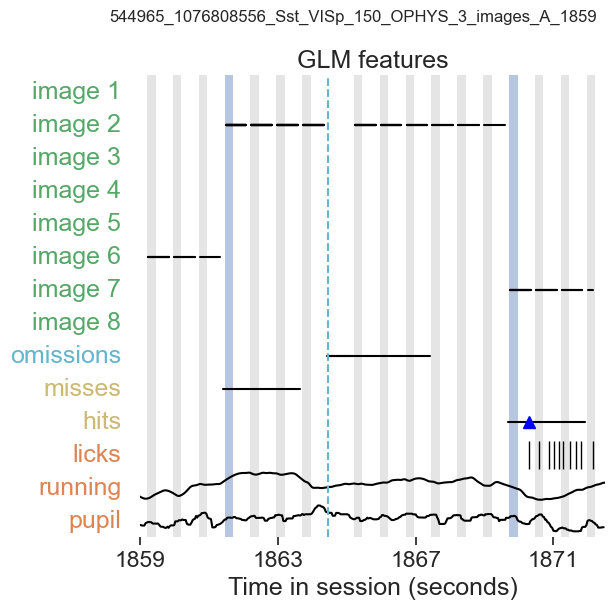

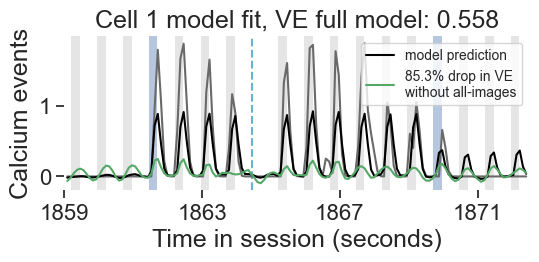

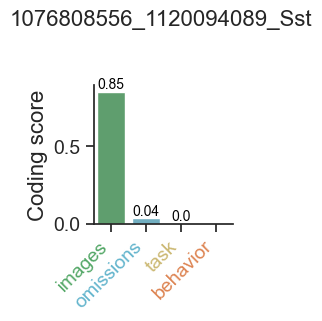

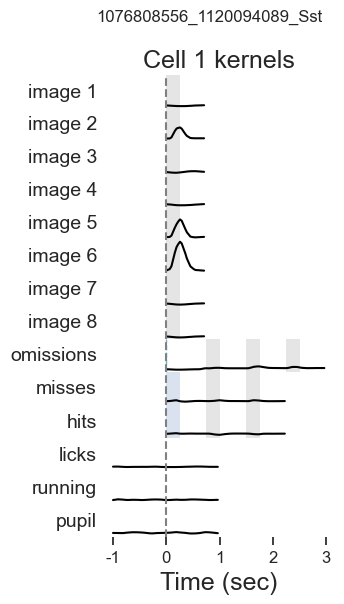

In [10]:
# 544965 - Sst - image coding
gep.plot_example_cell_all_panels(
    cell_specimen_id=1120094089,
    ophys_experiment_id=1076808556,
    start_time=1859,
    results_pivoted=results_pivoted,
    weights_df=weights_df,
    kernels=kernels,
    cell_label='Cell 1',
    save_dir=save_dir,
    folder='example_cells',
);

/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

[SAVE_FIGS=False] skipped figure save: 1859_544965_1076808560_Sst_VISp_75_OPHYS_3_images_A_1859.png
[SAVE_FIGS=False] skipped figure save: 1859_1120091606_544965_1076808560_Sst_VISp_75_OPHYS_3_images_A_model_fit_events_all-images.png
[SAVE_FIGS=False] skipped figure save: 1120091606_544965_1076808560_Sst_VISp_75_OPHYS_3_images_A_coding_scores.png


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/glm_example_plots.py:2273: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(feature_labels, rotation=45, horizontalalignment='right', fontsize=fontsize)


[SAVE_FIGS=False] skipped figure save: 1120091606_544965_1076808560_Sst_VISp_75_OPHYS_3_images_A_kernels.png


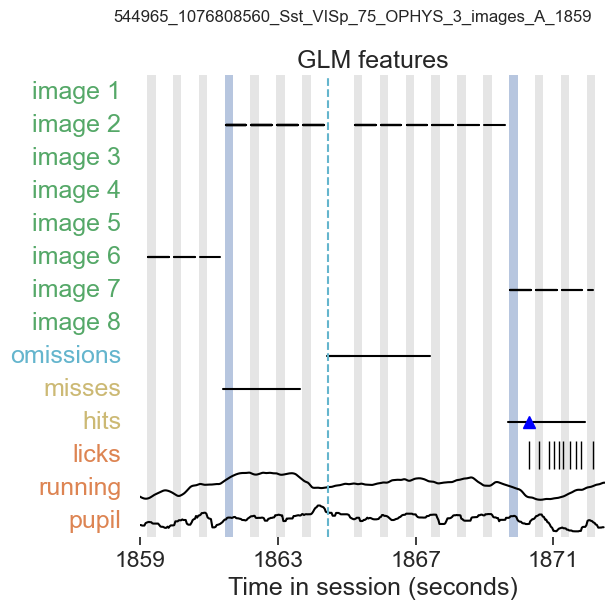

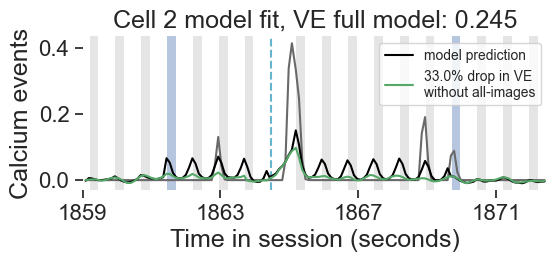

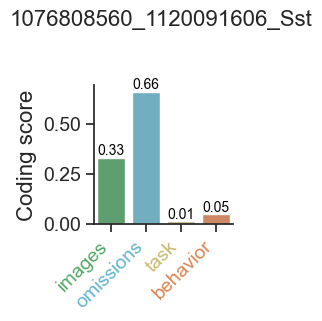

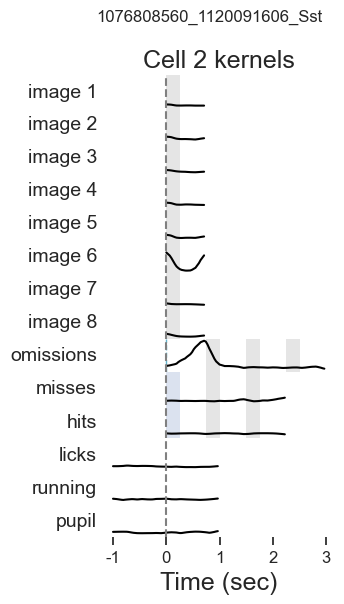

In [11]:
# 544965 - Sst - omission coding
gep.plot_example_cell_all_panels(
    cell_specimen_id=1120091606,
    ophys_experiment_id=1076808560,
    start_time=1859,
    results_pivoted=results_pivoted,
    weights_df=weights_df,
    kernels=kernels,
    cell_label='Cell 2',
    save_dir=save_dir,
    folder='example_cells',
);

#### Additional Vip examples

In [12]:
vips = results_pivoted[(results_pivoted.cell_type=='Vip Inhibitory') & 
                                    (results_pivoted.variance_explained_full>0.1) & 
                                    (results_pivoted['omissions']>0.5)].identifier.values

len(vips)

4

In [13]:
# Get saved example cells and event times of interest
example_cells_dict, example_times_dict = gep.get_glm_example_cells_and_times()
# Use custom selection
example_cells_dict = {974994093: [1086537043],
                        974994095: [1086519261],
                        974994101: [1086518655],
                        974994105: [1086524231],
                        # 905955213: [1086532875],
                        # 905955219: [1086509036],
                        1076808560: [1120091440, 1120091606],
                        1076808556: [1120094089, 1120094237, 1120094842]}


vip_example_cells_dict = {1053997501: [1086612555],
                        # 795953296: [1086490680],
                        851085100: [1086501664],
                        851085100: [1086501719]}

In [14]:
# folder = 'example_cells'

# for i, ophys_experiment_id in enumerate(list(vip_example_cells_dict.keys())):

#     ### Get data
#     dataset = loading.get_ophys_dataset(ophys_experiment_id)
#     cell_results_df, expt_results, dropouts = gep.load_glm_model_fit_results(ophys_experiment_id)

#     for cell_specimen_id in vip_example_cells_dict[ophys_experiment_id]:

        

#         ### Plot kernels and coding scores 
#         gep.plot_stacked_kernels_for_cell(cell_specimen_id, dataset, weights_df, kernels, 
#                                         save_dir=save_dir, folder=folder);

#         gep.plot_coding_score_components_for_cell(cell_specimen_id, ophys_experiment_id, results_pivoted, dataset,
#                                                     fontsize=14, as_panel=False, save_dir=save_dir, folder=folder);
    
#     ### Get time window
#     flashes_between_changes = 12
#     four_flash_dur = 6*0.75
#     start_times = utils.get_consecutive_trials_with_omission_in_middle(dataset, flashes_between_changes=flashes_between_changes)
#     for start_time in start_times[:5]:
#         xlim_seconds = [start_time, start_time+(flashes_between_changes*0.75)+four_flash_dur]
#         duration_seconds = (flashes_between_changes*0.75)+four_flash_dur
#         suffix = '_' + str(int(xlim_seconds[0]))

#         ### Plot GLM features 
#         gep.plot_glm_features_for_window(dataset, xlim_seconds, save_dir=save_dir, folder=folder, ax=None, suffix=suffix);

#         #### Plot model fit
#         gep.plot_model_fits_example_cell(cell_specimen_id, dataset, cell_results_df, dropouts, expt_results, 
#                                         'all-images', twinx=False, include_events=True, include_dff=False, 
#                                         times=xlim_seconds, save_dir=save_dir, folder=folder);     



#### Additional Sst & Excitatory examples

In [15]:
# folder = 'example_cells'

# for i, ophys_experiment_id in enumerate(list(example_cells_dict.keys())):
#     print(ophys_experiment_id)

#     ### Get data
#     dataset = loading.get_ophys_dataset(ophys_experiment_id)
#     cell_results_df, expt_results, dropouts = gep.load_glm_model_fit_results(ophys_experiment_id)

        
#     for cell_specimen_id in example_cells_dict[ophys_experiment_id]:

#         ### Get time window
#         start_time = example_times_dict[ophys_experiment_id][0]
#         flashes_between_changes = 12
#         four_flash_dur = 6*0.75
#         xlim_seconds = [start_time, start_time+(flashes_between_changes*0.75)+four_flash_dur]
#         duration_seconds = (flashes_between_changes*0.75)+four_flash_dur
#         suffix = '_' + str(int(xlim_seconds[0]))

#         ### Plot GLM features 
#         gep.plot_glm_features_for_window(dataset, xlim_seconds, save_dir=save_dir, folder=folder, ax=None, suffix=suffix);

#         #### Plot model fit
#         gep.plot_model_fits_example_cell(cell_specimen_id, dataset, cell_results_df, dropouts, expt_results, 
#                                         'all-images', twinx=False, include_events=True, include_dff=False, 
#                                     times=xlim_seconds, save_dir=save_dir, folder=folder);

#         ### Plot kernels and coding scores 
#         gep.plot_stacked_kernels_for_cell(cell_specimen_id, dataset, weights_df, kernels, 
#                                         save_dir=save_dir, folder=folder);

#         gep.plot_coding_score_components_for_cell(cell_specimen_id, ophys_experiment_id, results_pivoted, dataset,
#                                                     fontsize=14, as_panel=False, save_dir=save_dir, folder=folder);





### Image kernels for all cells 

[SAVE_FIGS=False] skipped figure save: all-images.png


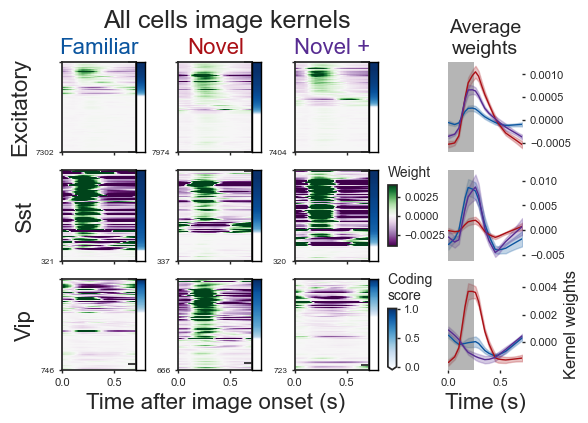

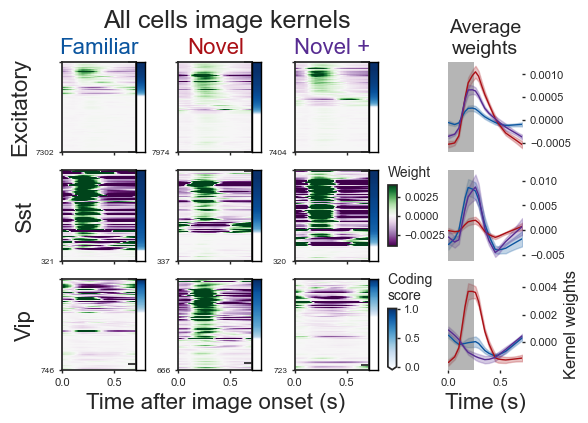

In [16]:
gep.plot_weights_and_coding_score_heatmaps_for_experience_levels_main_figure(
    'all-images', weights_df, run_params,
    row_condition='cre_line', col_condition='experience_level',
    vmax=0.004, xlabel='Time after image onset (s)', suptitle='All cells image kernels',
    save_dir=save_dir, folder='kernel_weights')


### Fraction cells coding for features

In [17]:
# Compute fraction of cells coding above threshold for each feature, per cre line
fractions = ppf.compute_feature_coding_fractions(results_pivoted, run_params, coding_thresh=0.1)

[SAVE_FIGS=False] skipped figure save: percent_cells_coding_feature.png
[SAVE_FIGS=False] skipped csv: percent_cells_coding_feature_values.csv


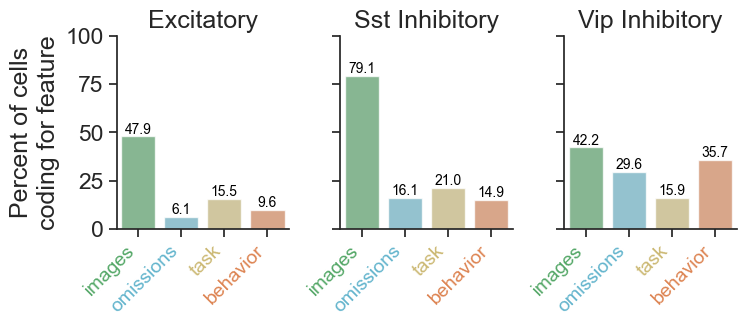

In [18]:
ppf.plot_percent_cells_coding_for_features(fractions, save_dir=save_dir, folder='coding_scores_and_kernels');

#### Maximally contributing feature 

/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:9402: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  results_avg = results_pivoted.groupby(['cre_line', 'cell_specimen_id']).mean().reset_index()


[SAVE_FIGS=False] skipped figure save: maximally_contributing_feature_dimension.png


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:9439: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([utils.get_abbreviated_cell_type(cre_line) for cre_line in utils.get_cre_lines()])


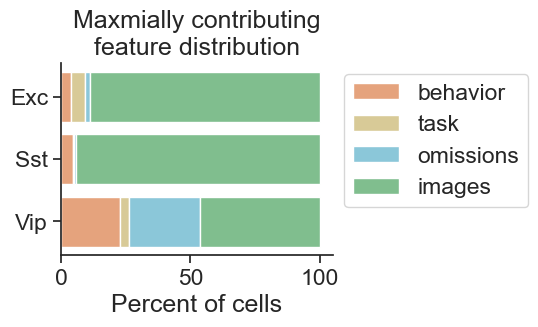

In [19]:
# Maximally contributing feature distribution
feature_counts = ppf.compute_maximally_contributing_feature(results_pivoted, matched_cells_table)
ppf.plot_maximally_contributing_feature_distribution(feature_counts, save_dir=save_dir, folder='coding_scores_and_kernels');

### Coding score distributions across experience levels

In [20]:
# Reshape coding scores for the four main features into long form for plotting
results_melted = ppf.convert_coding_scores_to_long_form_df(results_pivoted)
len(results_melted.ophys_experiment_id.unique())

402

/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:9564: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(exp_level_abbreviations)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:9564: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(exp_level_abbreviations)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:9564: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(exp_level_abbreviations)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_

[SAVE_FIGS=False] skipped figure save: coding_score_distributions_by_experience.png
[SAVE_FIGS=False] skipped csv: coding_score_distributions_by_experience_mlm.csv
[SAVE_FIGS=False] skipped csv: coding_score_distributions_by_experience_values.csv


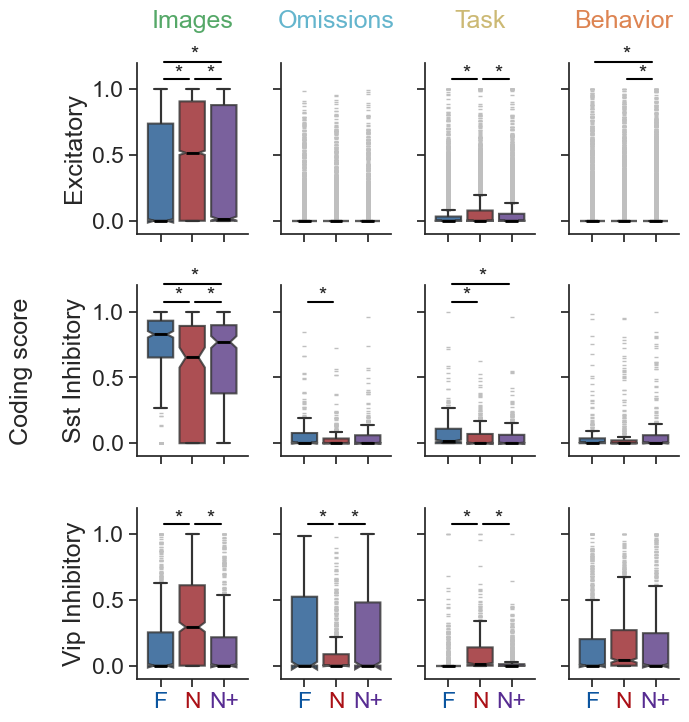

In [21]:
# Boxplots of coding score distributions by experience level, per cre line / feature
ppf.plot_coding_score_distributions_by_experience(
    results_melted, cre_lines=cre_lines,
    save_dir=save_dir, folder='coding_scores_and_kernels',
);

### Composite layout helpers (panel_grid)

Gutter-aware panel placement. Run this cell once before the composite cell.


In [22]:
from visual_behavior.visualization.panel_grid import (
    fig_setup, panel, panel_title, show_label_gutters, show_decoration_zones,
    check_label_overlap, auto_fit_left,
)


## Composite figure 


In [23]:
# ---- Preload example-cell data ONCE ----
# Run this cell a single time. After that you can edit + re-run the composite
# figure cell below as many times as you like without paying the (slow)
# loading.get_ophys_dataset / load_glm_model_fit_results cost each time.
# Re-running THIS cell is also cheap: it keeps anything already cached.
CELL1 = dict(cell_id=1120094089, expt_id=1076808556, label='Cell 1')
CELL2 = dict(cell_id=1120091606, expt_id=1076808560, label='Cell 2')

example_datasets = globals().get('example_datasets', {})
example_glm_fits = globals().get('example_glm_fits', {})   # expt_id -> (cell_results_df, expt_results, dropouts)
for _cell in (CELL1, CELL2):
    _eid = _cell['expt_id']
    if _eid not in example_datasets:
        print('loading dataset + GLM fits for experiment', _eid, '...')
        example_datasets[_eid] = loading.get_ophys_dataset(_eid)
        example_glm_fits[_eid] = gep.load_glm_model_fit_results(_eid)
print('cached experiments:', list(example_datasets))


loading dataset + GLM fits for experiment 1076808556 ...


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

loading dataset + GLM fits for experiment 1076808560 ...


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

cached experiments: [1076808556, 1076808560]


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/glm_example_plots.py:2273: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(feature_labels, rotation=45, horizontalalignment='right', fontsize=fontsize)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/glm_example_plots.py:2273: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(feature_labels, rotation=45, horizontalalignment='right', fontsize=fontsize)


[SAVE_FIGS=False] skipped csv: percent_cells_coding_feature_values.csv


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:9564: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(exp_level_abbreviations)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:9564: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(exp_level_abbreviations)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:9564: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(exp_level_abbreviations)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_

[SAVE_FIGS=False] skipped csv: coding_score_distributions_by_experience_mlm.csv
[SAVE_FIGS=False] skipped csv: coding_score_distributions_by_experience_values.csv
check_label_overlap: clean.
[SAVE_FIGS=False] skipped figure save: figure_4_main_composite.png
[SAVE_FIGS=False] skipped figure save: figure_4_main_composite.pdf


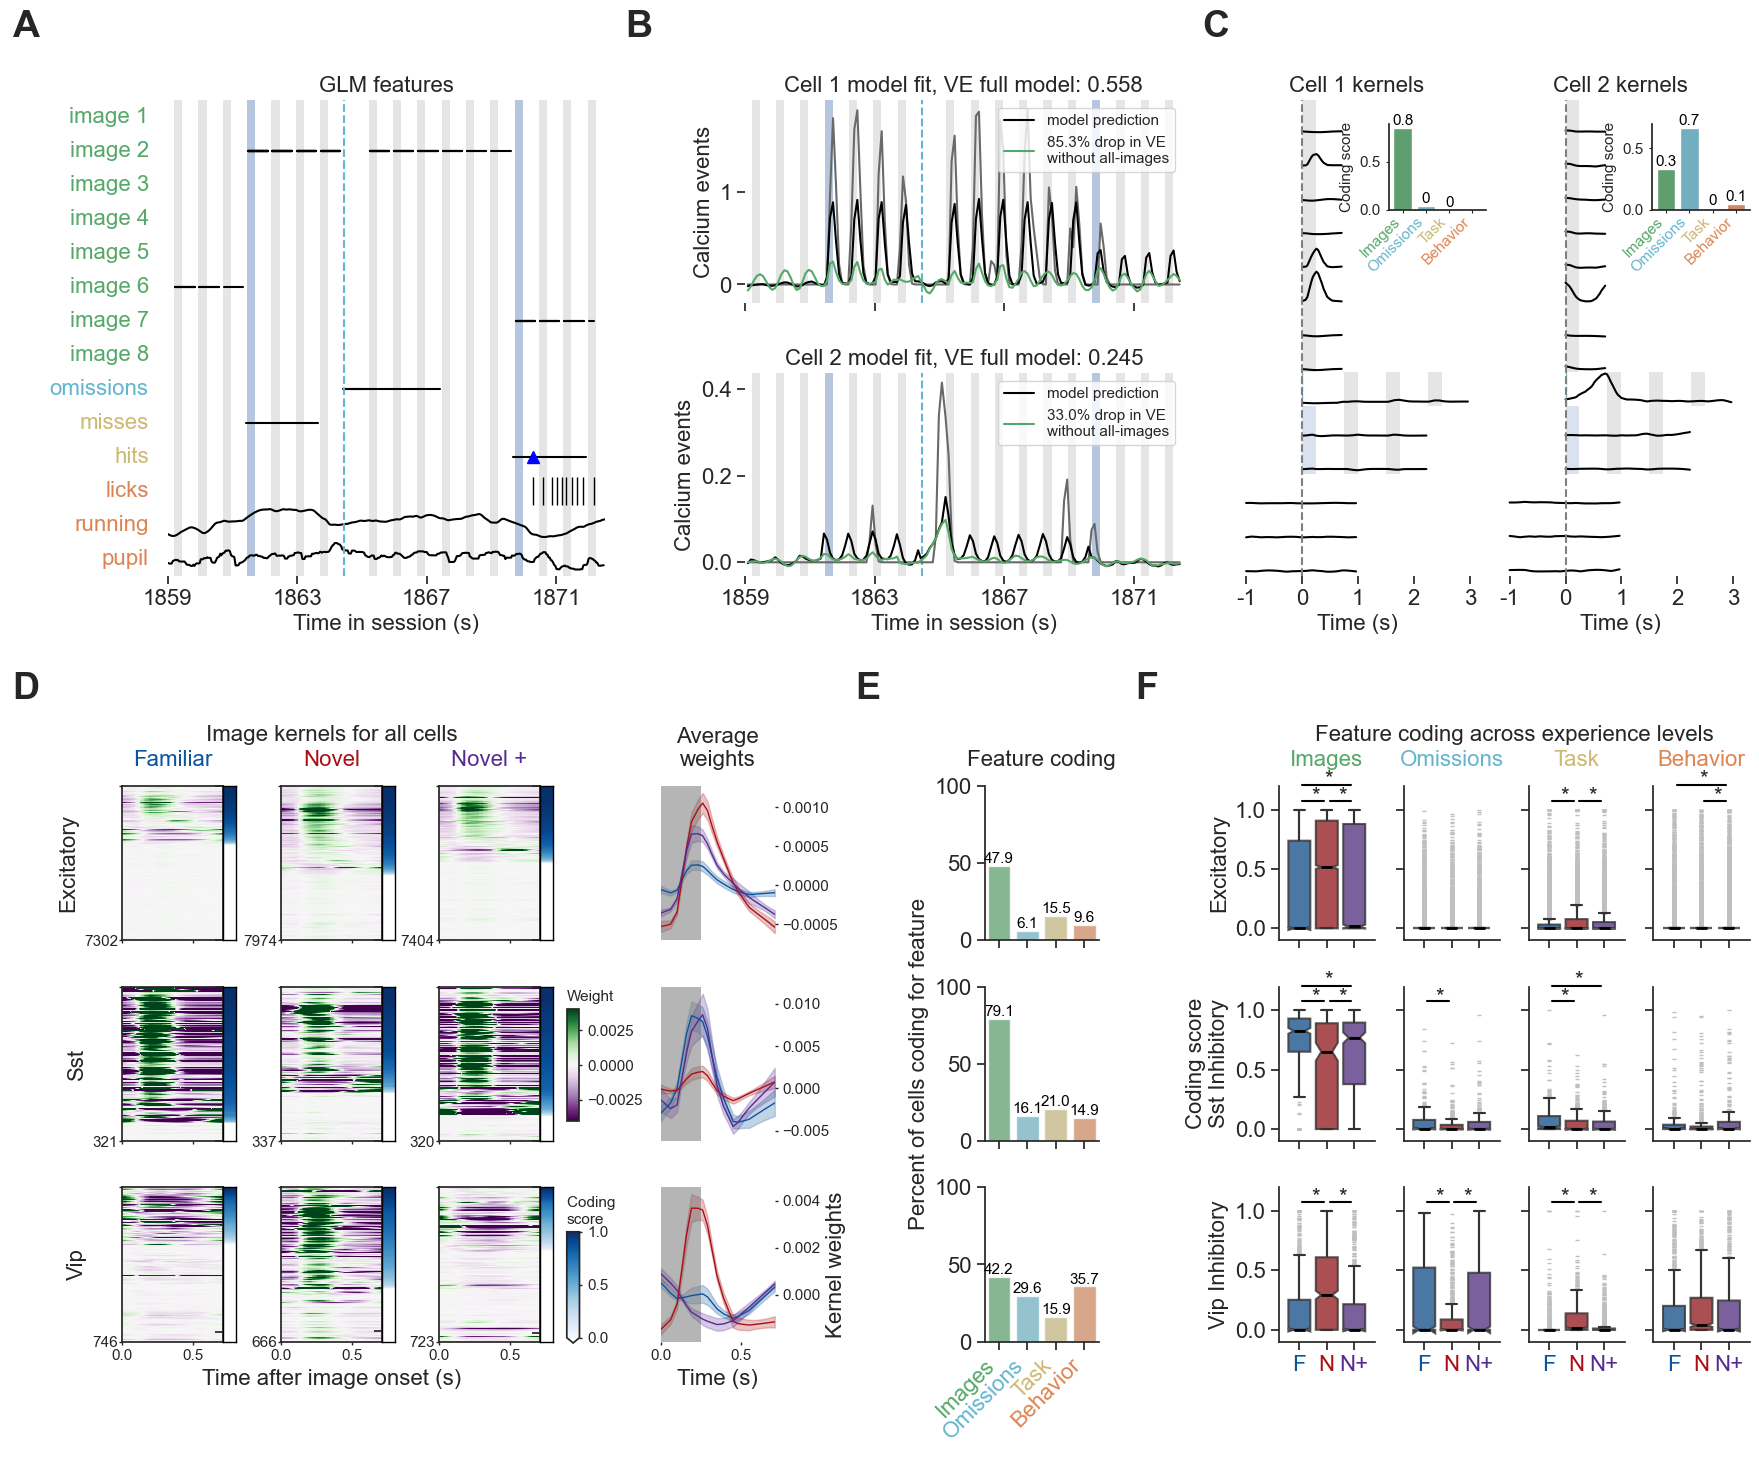

In [24]:
# Composite Figure 4 main - GLM coding analysis (cell-type-specific)
#   Row 1:  A GLM features | B Cell 1 + Cell 2 model fits | C Cell 1 + Cell 2 kernels (+ coding-score insets)
#   Row 2:  D All-cells image kernel heatmaps | E % cells coding (cell types stacked) | F Coding-score box plots
#
# LAYOUT (revision): two rows of three panels with matched heights. D, E and F
# share ONE grid y-extent (ROW2_GRID_Y) and ONE hspace (ROW2_HSPACE), so their
# Excitatory / Sst / Vip rows line up across the bottom row. E is drawn with
# cell types as rows (vertical=True) to match D and F.
#
# FONTS: every text element is mapped to one of two sizes at the end of the cell
# (LARGE_FS for axis labels / titles / headers / main tick labels; SMALL_FS for
# legends, insets, colorbars, annotations and the dense heatmap ticks in D).
import os, numpy as np

# ---------------- layout + font knobs (edit these) ----------------
FIG_W, FIG_H = 17.5, 14.4      # inches
figsize = (FIG_W, FIG_H)
LARGE_FS = 16      # axis labels, titles, row/column headers, main tick labels
SMALL_FS = 11      # legends, inset text, colorbars, value annotations, D tick labels
SPLIT_FS = 13      # any text drawn smaller than this becomes SMALL_FS, else LARGE_FS
LETTER_FS = 27     # panel letters

# vertical extents in INCHES from the top -> figure fraction
ROW1_Y = (0.00 / FIG_H, 5.63 / FIG_H)    # top row region
ROW2_Y = (6.66 / FIG_H, 1.000)           # bottom row region (gap above it = whitespace between rows)
def _fx(x0_in, x1_in):           # horizontal extents are given in INCHES -> figure fraction
    return [x0_in / FIG_W, x1_in / FIG_W]
REGIONS = {
    'A': [*_fx(0.00,  6.10), *ROW1_Y],
    'B': [*_fx(6.15, 11.85), *ROW1_Y],
    'C': [*_fx(11.90, 17.40), *ROW1_Y],
    'D': [*_fx(0.00,  8.29), *ROW2_Y],   # same physical width as the previous version
    'E': [*_fx(8.50, 10.90), *ROW2_Y],
    'F': [*_fx(11.30, 17.40), *ROW2_Y],
}
# D/E/F embedded grids share this y-extent so their rows align.
# Top inset holds: letter line + section title + column titles (Familiar / Images ...)
ROW2_GRID_Y = (ROW2_Y[0] + 1.07 / FIG_H, ROW2_Y[1] - 1.11 / FIG_H)
ROW2_HSPACE = 0.3
# per-panel left/right insets of the embedded D/E/F grids (inches)
D_INSET = (1.13, 0.82)   # left: cell-type labels + cell counts; right: 'Kernel weights' label
E_INSET = (1.25, 0.00)   # left: spanning y-label + 0/50/100 tick labels
F_INSET = (1.40, 0.00)   # left: 2-line 'Coding score / cell type' labels
AVG_XSPAN = (0.85, 1.03)   # D 'Average weights' column, fraction of D's grid width (>1 extends past it)
HEADER_PAD_PT = 14       # gap between the D/E/F column titles and their axes (clears F's significance bars)
SECTION_PAD_PT = 4       # gap between a section title and the column titles below it
C_WSPACE = 0.08          # gap between the Cell 1 / Cell 2 kernel columns in C
# ------------------------------------------------------------------

fig = plt.figure(figsize=figsize)
fig_setup(fig)
# per-panel stats/values from the embedded component plots are written to a
# dedicated stats folder inside the composite dir, mirroring figure 2
stats_dir = os.path.join(save_dir, 'composite', 'figure_4_stats') if save_dir else None

# CELL1, CELL2, example_datasets, example_glm_fits are defined in the
# "Preload example-cell data" cell above -- run that once, then this cell can be
# re-run repeatedly without re-loading datasets.
xlim_seconds = [1859, 1859 + 12*0.75 + 4.5]

# ---- A: GLM features (function needs an axes ARRAY of n_rows=14) ----
ax_A = panel(fig, REGIONS['A'][:2], REGIONS['A'][2:], 'A', has_title=True,
             dim=(14, 1), hspace=0.0, sharex=True,
             decoration_pt=(88, 0))   # >= 'omissions' row label
gep.plot_glm_features_for_window(
    dataset=example_datasets[CELL1['expt_id']],
    xlim_seconds=xlim_seconds, title='GLM features', ax=np.asarray(ax_A),
)

# ---- B: Cell 1 + Cell 2 model fits (stacked) ----
ax_B = panel(fig, REGIONS['B'][:2], REGIONS['B'][2:], 'B', has_title=True,
             dim=(2, 1), hspace=0.35, sharex=True,
             decoration_pt=(66, 0))   # 'Calcium events' label + tick labels
for ax, cell in zip(ax_B, [CELL1, CELL2]):
    dataset = example_datasets[cell['expt_id']]
    cell_results_df, expt_results, dropouts = example_glm_fits[cell['expt_id']]
    gep.plot_model_fits_example_cell(
        cell_specimen_id=cell['cell_id'], dataset=dataset,
        cell_results_df=cell_results_df, dropouts=dropouts, results=expt_results,
        kernel='all-images', include_events=True, include_dff=False,
        times=xlim_seconds, title=cell['label'] + ' model fit',
        twinx=False, fontsize=SMALL_FS, ax=ax,
    )
# share x across the two model-fit plots: only the bottom one shows ticks + label
ax_B[0].set_xlabel(''); ax_B[0].tick_params(labelbottom=False)

# ---- C: Cell 1 + Cell 2 kernels (14 stacked rows per column) with a SMALL
#         coding-score-bar inset in the upper-right of each column.
ax_C = panel(fig, REGIONS['C'][:2], REGIONS['C'][2:], 'C', has_title=True,
             dim=(14, 2), wspace=C_WSPACE, hspace=0.0, sharex=True, sharey='col',
             decoration_pt=(4, 0))    # row labels removed -> plots sit right next to the C label
# sharey='col' shares the y-axis across the 14 rows WITHIN each column (so kernel
# magnitudes are comparable down a column); the two cells keep independent scales.
# inset geometry as a fraction of each column's drawn extent -- tweak if needed
INSET_W_FRAC, INSET_H_FRAC, INSET_TOP_GAP, INSET_RIGHT_SHIFT = 0.40, 0.18, 0.05, 0.03
fig.canvas.draw()   # realize gridspec positions before measuring columns
for col, cell in enumerate([CELL1, CELL2]):
    dataset = example_datasets[cell['expt_id']]
    kernel_axes = [ax_C[r][col] for r in range(14)]
    # column title 'Cell N kernels' sits on the first kernel row (top of column)
    gep.plot_stacked_kernels_for_cell(
        cell_specimen_id=cell['cell_id'], dataset=dataset,
        weights_df=weights_df, kernels=kernels, sharey=True,
        title=cell['label'] + ' kernels',
        ax=kernel_axes, scale_y=False,
    )
    # row labels are identical to panel A, so omit them in C entirely
    for a in kernel_axes:
        a.set_ylabel('')
    # bottom-row x-tick labels: LARGE like the other main time axes (function forces 12)
    kernel_axes[-1].tick_params(axis='x', labelsize=LARGE_FS)
    # small coding-score inset in the column's upper-right
    left  = min(a.get_position().x0 for a in kernel_axes)
    right = max(a.get_position().x1 for a in kernel_axes)
    top   = max(a.get_position().y1 for a in kernel_axes)
    bot   = min(a.get_position().y0 for a in kernel_axes)
    col_w, col_h = right - left, top - bot
    iw, ih = col_w * INSET_W_FRAC, col_h * INSET_H_FRAC
    ix = right - iw + col_w * INSET_RIGHT_SHIFT
    iy = top - ih - col_h * INSET_TOP_GAP
    inset_ax = fig.add_axes([ix, iy, iw, ih])
    gep.plot_coding_score_components_for_cell(
        cell_specimen_id=cell['cell_id'], ophys_experiment_id=cell['expt_id'],
        results_pivoted=results_pivoted, dataset=dataset,
        title='', horiz=False, fontsize=SMALL_FS, as_panel=True,
        ax=inset_ax,
    )
    # as_panel=True despines all sides; restore the left + bottom spines
    for _s in ('left', 'bottom'):
        inset_ax.spines[_s].set_visible(True)
    # as_panel=True also calls set_xlim(0, 1), which clips this 4-bar vertical
    # plot to ~2 bars; restore the full categorical x-range so all 4 show
    inset_ax.set_xlim(-0.6, 3.6)
    # add capitalized feature x-tick labels, colored to match panel E
    _feat_colors, _ = plotting.get_feature_colors_and_labels()
    inset_ax.set_xticks(range(4))
    inset_ax.set_xticklabels(['Images', 'Omissions', 'Task', 'Behavior'],
                             rotation=45, ha='right', fontsize=SMALL_FS)
    for _t, _c in zip(inset_ax.get_xticklabels(), _feat_colors):
        _t.set_color(_c)
    # show x tick marks and pull the tick labels up close to the axis
    inset_ax.tick_params(axis='x', bottom=True, length=2.5, width=0.8, pad=1)
    inset_ax.tick_params(axis='y', left=True, length=2.5, width=0.8)
    inset_ax.yaxis.label.set_fontsize(SMALL_FS)   # function sets fontsize+2
    # coding-score value labels above bars: round to one decimal
    for _txt in inset_ax.texts:
        try:
            _v = float(_txt.get_text())
            _txt.set_text('0' if round(_v, 1) == 0 else f"{_v:.1f}")
            _txt.set_fontsize(SMALL_FS)
        except ValueError:
            pass

# ---- D: All-cells image kernels heatmap matrix (live, embedded) ----
# Cell types are rows; Familiar / Novel / Novel+ are columns. The grid's y-extent
# and hspace are shared with E and F so the three panels' rows line up.
ax_D = panel(fig, REGIONS['D'][:2], REGIONS['D'][2:], 'D')
ax_D.axis('off')
_bbox_D = (REGIONS['D'][0] + D_INSET[0] / FIG_W, ROW2_GRID_Y[0],
           REGIONS['D'][1] - D_INSET[1] / FIG_W, ROW2_GRID_Y[1])
gep.plot_weights_and_coding_score_heatmaps_for_experience_levels_main_figure(
    'all-images', weights_df, run_params,
    row_condition='cre_line', col_condition='experience_level',
    vmax=0.004, xlabel='Time after image onset (s)',
    fig=fig, bbox=_bbox_D, add_suptitle=False, hspace=ROW2_HSPACE, avg_xspan=AVG_XSPAN,
    xtick_fontsize=SMALL_FS, cell_count_fontsize=SMALL_FS, avg_ytick_fontsize=SMALL_FS,
    colorbar_title_fontsize=SMALL_FS, colorbar_tick_fontsize=SMALL_FS, ytick_pad=1,
)

# 'Kernel weights' y-label: large like the other axis labels (function hard-codes 12)
for _a in fig.axes:
    if _a.get_ylabel() == 'Kernel weights':
        _a.yaxis.label.set_fontsize(LARGE_FS)

# ---- E: Percent of cells coding for feature, cell types as ROWS (fig=, bbox=) ----
ax_E = panel(fig, REGIONS['E'][:2], REGIONS['E'][2:], 'E')
ax_E.axis('off')
_bbox_E = (REGIONS['E'][0] + E_INSET[0] / FIG_W, ROW2_GRID_Y[0],
           REGIONS['E'][1] - E_INSET[1] / FIG_W, ROW2_GRID_Y[1])
_, ax_E_grid = ppf.plot_percent_cells_coding_for_features(
    fractions, stats_dir=stats_dir, fig=fig, bbox=_bbox_E,
    vertical=True, hspace=ROW2_HSPACE,
)
# capitalize the feature x-tick labels (preserve their per-feature colors).
# Bottom row only: rows share x, so relabeling a hidden row would blank the bottom one.
for _a in np.ravel(ax_E_grid)[-1:]:
    _cols = [t.get_color() for t in _a.get_xticklabels()]
    _a.set_xticklabels([t.get_text().capitalize() for t in _a.get_xticklabels()],
                       rotation=45, ha='right')
    for _t, _c in zip(_a.get_xticklabels(), _cols):
        _t.set_color(_c)

# ---- F: Coding-score box plot grid (fig=, bbox=) ----
ax_F = panel(fig, REGIONS['F'][:2], REGIONS['F'][2:], 'F')
ax_F.axis('off')
_bbox_F = (REGIONS['F'][0] + F_INSET[0] / FIG_W, ROW2_GRID_Y[0],
           REGIONS['F'][1] - F_INSET[1] / FIG_W, ROW2_GRID_Y[1])
_, ax_F_grid, _ = ppf.plot_coding_score_distributions_by_experience(
    results_melted, cre_lines=cre_lines, stats_dir=stats_dir, fig=fig, bbox=_bbox_F,
)
# y is shared (sharey=True in the embedded grid); show y-tick labels on the
# leftmost column only (grid is len(cre_lines) x len(features), row-major)
_axF_flat = np.ravel(ax_F_grid)
_ncol_F = len(_axF_flat) // len(cre_lines)
for _i, _a in enumerate(_axF_flat):
    if _i % _ncol_F != 0:
        _a.tick_params(labelleft=False)
# middle-row y-label: collapse the blank line -> 'Coding score\n<cell type>'
for _a in _axF_flat:
    _yl = _a.get_ylabel()
    if '\n\n' in _yl:
        _a.yaxis.label.set_text(_yl.replace('\n\n', '\n'))
# feature titles on the top row: drop the trailing blank line so they sit right
# above the axes, at the same height as D's Familiar / Novel / Novel+ titles
for _a in _axF_flat[:_ncol_F]:
    _a.set_title(_a.get_title().rstrip('\n'), color=_a.title.get_color())

# standardize time-axis unit labels to "(s)" (A: 'seconds', C: 'sec')
for _a in fig.axes:
    _xl = _a.get_xlabel()
    if '(seconds)' in _xl or '(sec)' in _xl:
        _a.xaxis.label.set_text(_xl.replace('(seconds)', '(s)').replace('(sec)', '(s)'))

# ---- Two-size font pass: every text -> SMALL_FS or LARGE_FS ----
def _two_size(fs):
    return SMALL_FS if fs < SPLIT_FS else LARGE_FS
fig.canvas.draw()   # realize tick labels so their current sizes can be read
for _a in fig.axes:
    if getattr(_a, '_panel_grid_label_ax', False):
        continue
    for _name, _axis in (('x', _a.xaxis), ('y', _a.yaxis)):
        _tl = [t for t in _axis.get_ticklabels() if t.get_text()]
        if _tl:
            _a.tick_params(axis=_name, labelsize=_two_size(_tl[0].get_fontsize()))
    _texts = [_a.title, _a._left_title, _a._right_title, _a.xaxis.label, _a.yaxis.label,
              _a.xaxis.offsetText, _a.yaxis.offsetText] + list(_a.texts)
    if _a.get_legend() is not None:
        _texts += list(_a.get_legend().get_texts())
    for _t in _texts:
        if _t.get_text():
            _t.set_fontsize(_two_size(_t.get_fontsize()))
for _t in fig.texts:
    _t.set_fontsize(_two_size(_t.get_fontsize()))
for _lax in fig.axes:                       # panel letters
    if getattr(_lax, '_panel_grid_label_ax', False):
        for _lt in _lax.texts:
            _lt.set_fontsize(LETTER_FS)

# ---- Column titles on the D/E/F header line: E gets its title here; then lift all
#      header titles (D Familiar/Novel/Novel+ + Average weights, E, F features) by the
#      same pad so they clear F's significance bars and stay aligned ----
_e_top = np.ravel(ax_E_grid)[0]
_e_top.set_title('Feature coding', fontsize=LARGE_FS)
_grid_top = 1 - ROW2_GRID_Y[0]
for _a in fig.axes:
    if _a.get_title() and abs(_a.get_position().y1 - _grid_top) < 0.01:
        _a.set_title(_a.get_title(), color=_a.title.get_color(),
                     fontsize=_a.title.get_fontsize(), pad=HEADER_PAD_PT)

# ---- Section titles for D / F: one line just above the column titles ----
# (Familiar / Novel / Novel+ in D, Images / Omissions / ... in F), same size as them
fig.canvas.draw()
_r = fig.canvas.get_renderer()
_inv = fig.transFigure.inverted()
_novel_lbl = utils.convert_experience_level('Novel')
def _in_region(a, lbl):
    p = a.get_position(); x0, x1, y0, y1 = REGIONS[lbl]
    return x0 <= (p.x0 + p.x1) / 2 <= x1 and (1 - y1) <= (p.y0 + p.y1) / 2 <= (1 - y0)
_novel_ax = [a for a in fig.axes if a.get_title() == _novel_lbl and _in_region(a, 'D')][0]
_hdr_top = _novel_ax.title.get_window_extent(_r).transformed(_inv).y1     # top of the column titles
_sec_y = _hdr_top + SECTION_PAD_PT / 72.0 / FIG_H
_sec_fs = _novel_ax.title.get_fontsize()
def _span(axes):
    return min(a.get_position().x0 for a in axes), max(a.get_position().x1 for a in axes)
_sections = {
    'D': ('Image kernels for all cells', (0.5 * sum(_novel_ax.get_position().intervalx),) * 2),
    'F': ('Feature coding across experience levels', _span(_axF_flat)),
}
for _lbl, (_txt, (_x0, _x1)) in _sections.items():
    fig.text((_x0 + _x1) / 2, _sec_y, _txt, ha='center', va='bottom', fontsize=_sec_fs)

# ---- Audit ----
check_label_overlap(fig, REGIONS)
utils.save_figure(fig, figsize, save_dir, 'composite', 'figure_4_main_composite', formats=['.png', '.pdf'])